# <center> Employee Retention Prediction <center>
![Screenshot%202025-08-28%20125123.png](attachment:Screenshot%202025-08-28%20125123.png)

### Agenda:
1. [Frame the Problem / Business Case](#problem)
2. [Gathering the Data](#data)
3. [Data Pre-Pocessing](#processing)
4. [EDA](#eda)
5. [Feature Engineering](#engg)
6. [Model Training, Evaluation and Selection](#model)

<a id='problem'></a>

## 1. Frame the Problem / Business Case

### Background:
- Hiring and retaining employees are extremely complex tasks that require capital, time and skills
- Small business owners spend **40% of their working** hours on tasks that do **not** generate any income such as hiring
- Companies spend **15%-20%** of the employee's salary to recruit a new candidate
- An average company loses anywhere **between 1% and 2.5%** of their total revenue on the time it takes to bring a new hire up to speed
- It takes **52 days** on average to fill a position

### Problem Statement:
- You work as a data scientist at a Multi-National Corporation
- The HR team collected extensive data on their employees and approached you to develop a model that could predict which employees are more likely to quit
- The team provided you with an extensive dataset, a sample of which is provided:
    - JobInvolvement
    - Education
    - JobSatisfaction
    - PerformanceRating
    - RelationshipSatisfaction
    - WorkLifeBalance

<a id='data'></a>

## 2. Gathering the Data

In [21]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from google.colab import files
from IPython.display import display

print("Libraries imported succesfully!")


Libraries imported succesfully!


In [22]:
uploaded = files.upload()
file_name = next(iter(uploaded.keys()))
df = pd.read_csv(file_name)
print("Dataset loaded successfully!")

Saving Human_Resources.csv to Human_Resources.csv
Dataset loaded successfully!


In [26]:
display(df.head())

,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EmployeeCount,EmployeeNumber,...,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
0,41,Yes,Travel_Rarely,1102,Sales,1,2,Life Sciences,1,1,...,1,80,0,8,0,1,6,4,0,5
1,49,No,Travel_Frequently,279,Research & Development,8,1,Life Sciences,1,2,...,4,80,1,10,3,3,10,7,1,7
2,37,Yes,Travel_Rarely,1373,Research & Development,2,2,Other,1,4,...,2,80,0,7,3,3,0,0,0,0
3,33,No,Travel_Frequently,1392,Research & Development,3,4,Life Sciences,1,5,...,3,80,0,8,3,3,8,7,3,0
4,27,No,Travel_Rarely,591,Research & Development,2,1,Medical,1,7,...,4,80,1,6,3,3,2,2,2,2


In [27]:
display(df.tail())

,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EmployeeCount,EmployeeNumber,...,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
1465,36,No,Travel_Frequently,884,Research & Development,23,2,Medical,1,2061,...,3,80,1,17,3,3,5,2,0,3
1466,39,No,Travel_Rarely,613,Research & Development,6,1,Medical,1,2062,...,1,80,1,9,5,3,7,7,1,7
1467,27,No,Travel_Rarely,155,Research & Development,4,3,Life Sciences,1,2064,...,2,80,1,6,0,3,6,2,0,3
1468,49,No,Travel_Frequently,1023,Sales,2,3,Medical,1,2065,...,4,80,0,17,3,2,9,6,0,8
1469,34,No,Travel_Rarely,628,Research & Development,8,3,Medical,1,2068,...,1,80,0,6,3,4,4,3,1,2


In [28]:
print("Dataset shape:", df.shape)

Dataset shape: (1470, 35)


In [29]:
print("\nColumn names:")
print(df.columns.tolist())


Column names:
['Age', 'Attrition', 'BusinessTravel', 'DailyRate', 'Department', 'DistanceFromHome', 'Education', 'EducationField', 'EmployeeCount', 'EmployeeNumber', 'EnvironmentSatisfaction', 'Gender', 'HourlyRate', 'JobInvolvement', 'JobLevel', 'JobRole', 'JobSatisfaction', 'MaritalStatus', 'MonthlyIncome', 'MonthlyRate', 'NumCompaniesWorked', 'Over18', 'OverTime', 'PercentSalaryHike', 'PerformanceRating', 'RelationshipSatisfaction', 'StandardHours', 'StockOptionLevel', 'TotalWorkingYears', 'TrainingTimesLastYear', 'WorkLifeBalance', 'YearsAtCompany', 'YearsInCurrentRole', 'YearsSinceLastPromotion', 'YearsWithCurrManager']


In [30]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1470 entries, 0 to 1469
Data columns (total 35 columns):
 #   Column                    Non-Null Count  Dtype 
---  ------                    --------------  ----- 
 0   Age                       1470 non-null   int64 
 1   Attrition                 1470 non-null   object
 2   BusinessTravel            1470 non-null   object
 3   DailyRate                 1470 non-null   int64 
 4   Department                1470 non-null   object
 5   DistanceFromHome          1470 non-null   int64 
 6   Education                 1470 non-null   int64 
 7   EducationField            1470 non-null   object
 8   EmployeeCount             1470 non-null   int64 
 9   EmployeeNumber            1470 non-null   int64 
 10  EnvironmentSatisfaction   1470 non-null   int64 
 11  Gender                    1470 non-null   object
 12  HourlyRate                1470 non-null   int64 
 13  JobInvolvement            1470 non-null   int64 
 14  JobLevel                

In [31]:
display(df.describe().T)

,count,mean,std,min,25%,50%,75%,max
Age,1470.0,36.923810,9.135373,18.0,30.00,36.0,43.00,60.0
DailyRate,1470.0,802.485714,403.509100,102.0,465.00,802.0,1157.00,1499.0
DistanceFromHome,1470.0,9.192517,8.106864,1.0,2.00,7.0,14.00,29.0
Education,1470.0,2.912925,1.024165,1.0,2.00,3.0,4.00,5.0
EmployeeCount,1470.0,1.000000,0.000000,1.0,1.00,1.0,1.00,1.0
EmployeeNumber,1470.0,1024.865306,602.024335,1.0,491.25,1020.5,1555.75,2068.0
EnvironmentSatisfaction,1470.0,2.721769,1.093082,1.0,2.00,3.0,4.00,4.0
HourlyRate,1470.0,65.891156,20.329428,30.0,48.00,66.0,83.75,100.0
JobInvolvement,1470.0,2.729932,0.711561,1.0,2.00,3.0,3.00,4.0
JobLevel,1470.0,2.063946,1.106940,1.0,1.00,2.0,3.00,5.0


In [32]:
display(df.describe(include="all").T)

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Age,1470.0,NaN,NaN,NaN,36.92381,9.135373,18.0,30.0,36.0,43.0,60.0
Attrition,1470,2,No,1233,NaN,NaN,NaN,NaN,NaN,NaN,NaN
BusinessTravel,1470,3,Travel_Rarely,1043,NaN,NaN,NaN,NaN,NaN,NaN,NaN
DailyRate,1470.0,NaN,NaN,NaN,802.485714,403.5091,102.0,465.0,802.0,1157.0,1499.0
Department,1470,3,Research & Development,961,NaN,NaN,NaN,NaN,NaN,NaN,NaN
DistanceFromHome,1470.0,NaN,NaN,NaN,9.192517,8.106864,1.0,2.0,7.0,14.0,29.0
Education,1470.0,NaN,NaN,NaN,2.912925,1.024165,1.0,2.0,3.0,4.0,5.0
EducationField,1470,6,Life Sciences,606,NaN,NaN,NaN,NaN,NaN,NaN,NaN
EmployeeCount,1470.0,NaN,NaN,NaN,1.0,0.0,1.0,1.0,1.0,1.0,1.0
EmployeeNumber,1470.0,NaN,NaN,NaN,1024.865306,602.024335,1.0,491.25,1020.5,1555.75,2068.0


<a id='processing'></a>

## 3. Data Pre-Pocessing

In [33]:
print("missing values per colum")
print(df.isnull().sum())

missing values per colum
Age                         0
Attrition                   0
BusinessTravel              0
DailyRate                   0
Department                  0
DistanceFromHome            0
Education                   0
EducationField              0
EmployeeCount               0
EmployeeNumber              0
EnvironmentSatisfaction     0
Gender                      0
HourlyRate                  0
JobInvolvement              0
JobLevel                    0
JobRole                     0
JobSatisfaction             0
MaritalStatus               0
MonthlyIncome               0
MonthlyRate                 0
NumCompaniesWorked          0
Over18                      0
OverTime                    0
PercentSalaryHike           0
PerformanceRating           0
RelationshipSatisfaction    0
StandardHours               0
StockOptionLevel            0
TotalWorkingYears           0
TrainingTimesLastYear       0
WorkLifeBalance             0
YearsAtCompany              0
YearsInCurrentR

In [34]:
print("\n total missing values")
print(df.isnull().sum().sum())


 total missing values
0


In [35]:
print("\n duplicate rows")
print(df.duplicated().sum())


 duplicate rows
0


In [36]:

df_original = df.copy()


columns_to_drop = [
    "EmployeeCount",
    "Over18",
    "StandardHours",
    "EmployeeNumber"
]

df = df.drop(
    columns=columns_to_drop,
    errors="ignore"
)

print("Unnecessary columns removed.")
print("Updated dataset shape:", df.shape)

display(df.head())

Unnecessary columns removed.
Updated dataset shape: (1470, 31)


,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EnvironmentSatisfaction,Gender,...,PerformanceRating,RelationshipSatisfaction,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
0,41,Yes,Travel_Rarely,1102,Sales,1,2,Life Sciences,2,Female,...,3,1,0,8,0,1,6,4,0,5
1,49,No,Travel_Frequently,279,Research & Development,8,1,Life Sciences,3,Male,...,4,4,1,10,3,3,10,7,1,7
2,37,Yes,Travel_Rarely,1373,Research & Development,2,2,Other,4,Male,...,3,2,0,7,3,3,0,0,0,0
3,33,No,Travel_Frequently,1392,Research & Development,3,4,Life Sciences,4,Female,...,3,3,0,8,3,3,8,7,3,0
4,27,No,Travel_Rarely,591,Research & Development,2,1,Medical,1,Male,...,3,4,1,6,3,3,2,2,2,2


In [37]:
print("Attrition counts:")
print(df["Attrition"].value_counts())

print("\nAttrition percentage:")
print(
    (df["Attrition"].value_counts(normalize=True) * 100)
    .round(2))

Attrition counts:
Attrition
No     1233
Yes     237
Name: count, dtype: int64

Attrition percentage:
Attrition
No     83.88
Yes    16.12
Name: proportion, dtype: float64


<a id='eda'></a>

## 4. Exploratory Data Analysis (EDA)

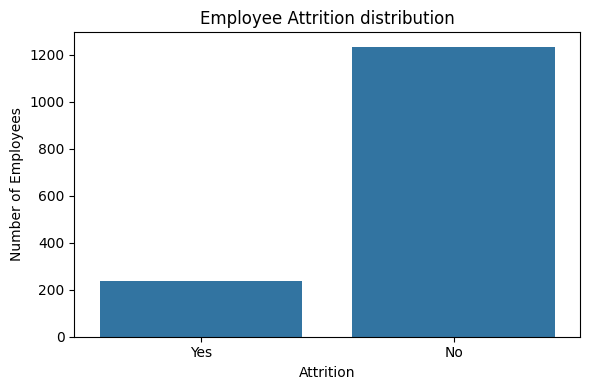

In [24]:
#1. Attrition distribution
plt.figure(figsize=(6,4))

sns.countplot(data=df, x="Attrition")

plt.title("Employee Attrition distribution")
plt.xlabel("Attrition")
plt.ylabel("Number of Employees")

plt.tight_layout()
plt.show()

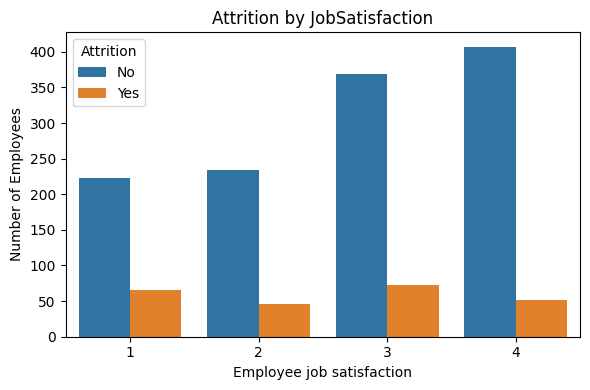

In [29]:
#2. Attrition by Job satisfaction
plt.figure(figsize=(6,4))

sns.countplot(data=df, x="JobSatisfaction", hue="Attrition")

plt.title("Attrition by JobSatisfaction")
plt.xlabel("Employee job satisfaction")
plt.ylabel("Number of Employees")

plt.tight_layout()
plt.show()

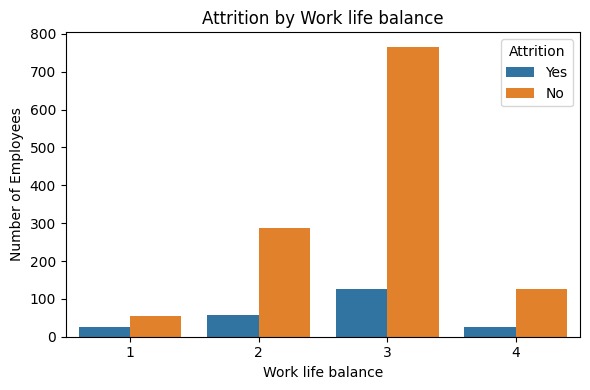

In [31]:
#3. Attrition by Work life balance
plt.figure(figsize=(6,4))

sns.countplot(data=df, x="WorkLifeBalance", hue="Attrition")

plt.title("Attrition by Work life balance")
plt.xlabel("Work life balance")
plt.ylabel("Number of Employees")

plt.tight_layout()
plt.show()

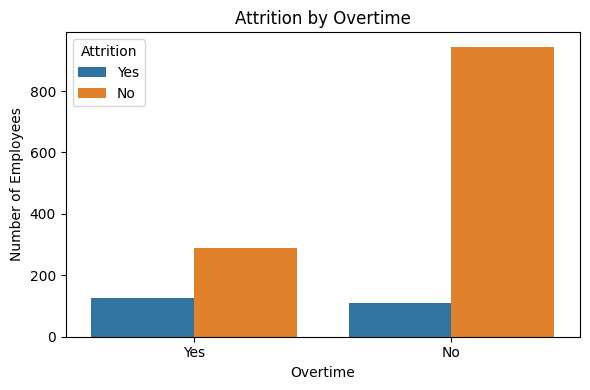

In [33]:
#4. Attrition by Overtime
plt.figure(figsize=(6,4))

sns.countplot(data=df, x="OverTime", hue="Attrition")

plt.title("Attrition by Overtime")
plt.xlabel("Overtime")
plt.ylabel("Number of Employees")

plt.tight_layout()
plt.show()

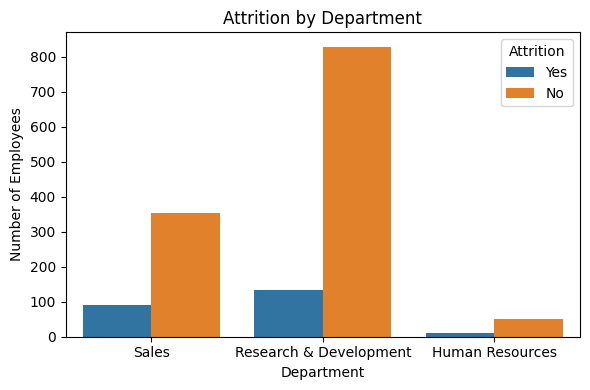

In [37]:
#5. Attrition by Department
plt.figure(figsize=(6,4))

sns.countplot(data=df, x="Department", hue="Attrition")

plt.title("Attrition by Department")
plt.xlabel("Department")
plt.ylabel("Number of Employees")


plt.tight_layout()
plt.show()

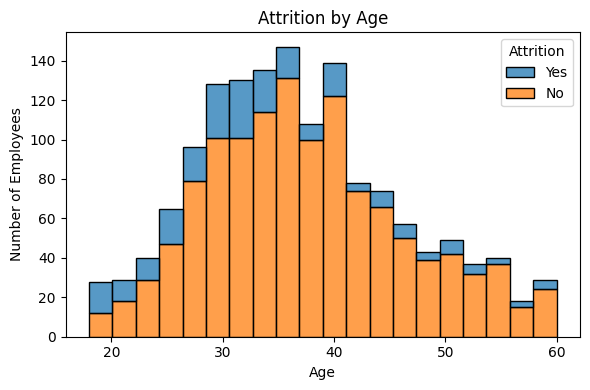

In [43]:
#6. Attrition by Age
plt.figure(figsize=(6,4))

sns.histplot(data=df, x="Age", hue="Attrition", multiple="stack", bins=20)

plt.title("Attrition by Age")
plt.xlabel("Age")
plt.ylabel("Number of Employees")


plt.tight_layout()
plt.show()

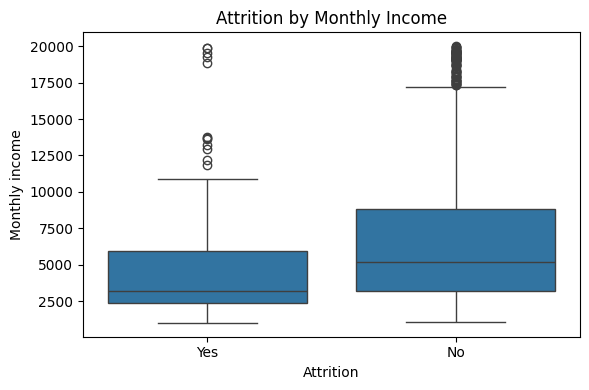

In [48]:
#7. Attrition by Monthly Income
plt.figure(figsize=(6,4))

sns.boxplot(data=df, x="Attrition", y="MonthlyIncome")
plt.title("Attrition by Monthly Income")
plt.xlabel("Attrition")
plt.ylabel("Monthly income")


plt.tight_layout()
plt.show()

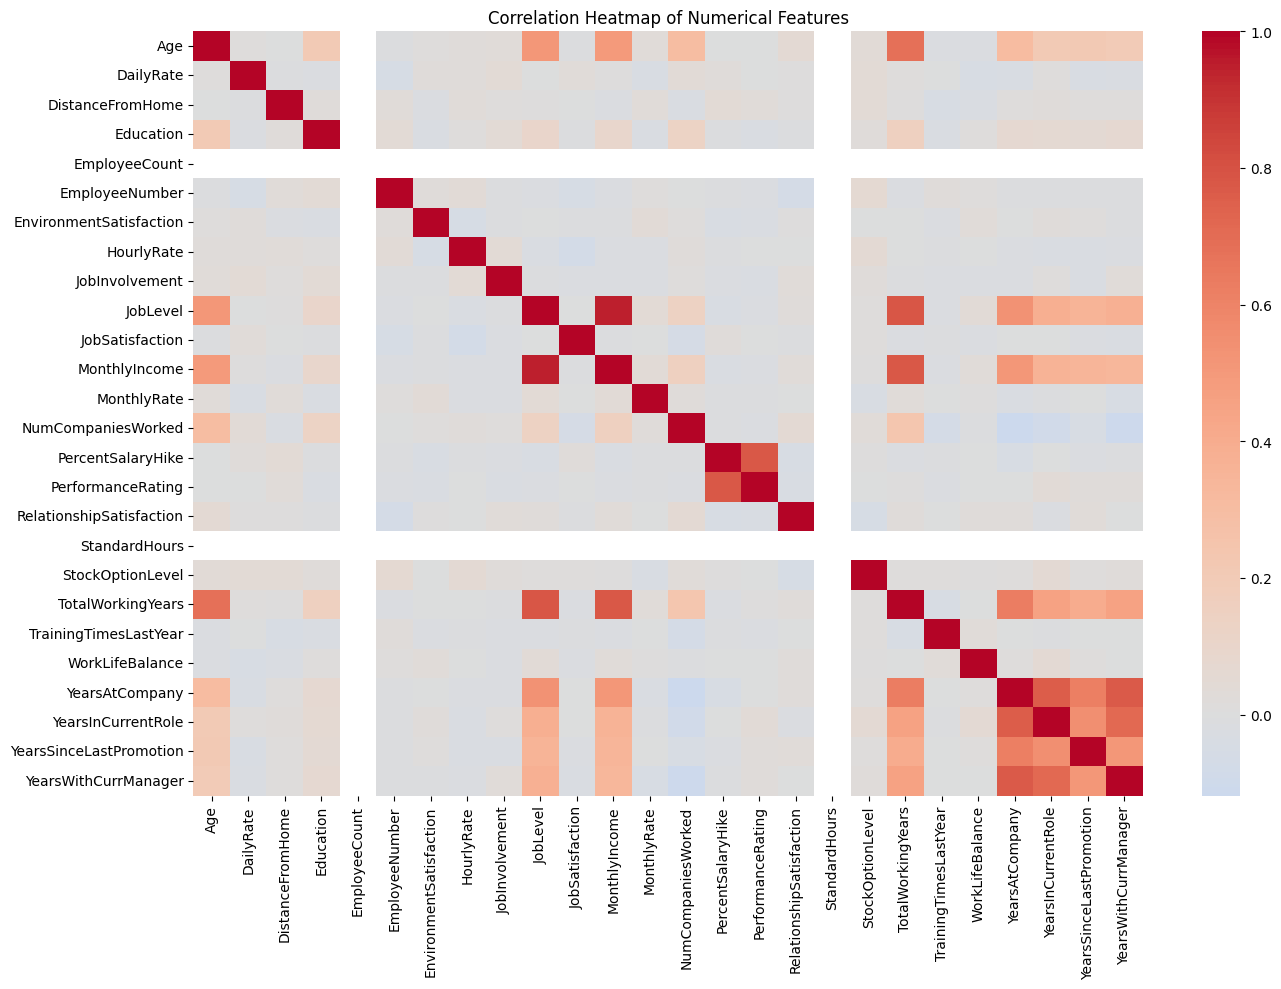

In [7]:
#8. Correlation Heatmap

numeric_df = df.select_dtypes(include=np.number)

plt.figure(figsize=(14, 10))

sns.heatmap(
    numeric_df.corr(),
    cmap="coolwarm",
    center=0
)

plt.title("Correlation Heatmap of Numerical Features")
plt.tight_layout()
plt.show()


In [38]:
# EDA Summary Statistics

print("Total employees:", len(df))

print("\nAttrition distribution:")
display(df["Attrition"].value_counts().to_frame("Count"))

print("\nAttrition rate:")
print(
    f"{(df['Attrition'].eq('Yes').mean() * 100):.2f}%"
)

print("\nAverage age by attrition:")
display(df.groupby("Attrition")["Age"].mean().round(2))

print("\nAverage monthly income by attrition:")
display(
    df.groupby("Attrition")["MonthlyIncome"]
    .mean()
    .round(2)
)

print("\nOvertime by attrition:")
display(pd.crosstab(df["OverTime"], df["Attrition"]))

Total employees: 1470

Attrition distribution:


,Count
Attrition,
No,1233
Yes,237



Attrition rate:
16.12%

Average age by attrition:


,Age
Attrition,
No,37.56
Yes,33.61



Average monthly income by attrition:


,MonthlyIncome
Attrition,
No,6832.74
Yes,4787.09



Overtime by attrition:


Attrition,No,Yes
OverTime,,
No,944,110
Yes,289,127


<a id='engg'></a>

## 5. Feature Engineering

In [39]:
#1. Separate input features and target


# Restore the original dataset
df = df_original.copy()

# Remove unnecessary columns
columns_to_drop = [
    "EmployeeCount",
    "Over18",
    "StandardHours",
    "EmployeeNumber"
]

df = df.drop(columns=columns_to_drop, errors="ignore")

# Clean spaces around target values
df["Attrition"] = df["Attrition"].astype("string").str.strip()

# Remove rows where the target is genuinely missing
df = df.dropna(subset=["Attrition"]).copy()

# Standardize target values
df["Attrition"] = df["Attrition"].str.lower()

# Check for unexpected values
print("Attrition values before encoding:")
print(df["Attrition"].value_counts(dropna=False))

unexpected = ~df["Attrition"].isin(["yes", "no"])

if unexpected.any():
    print("Unexpected target values:")
    print(df.loc[unexpected, "Attrition"].unique())
    raise ValueError("Please inspect the unexpected Attrition values.")

# Encode target
df["Attrition"] = df["Attrition"].map({
    "no": 0,
    "yes": 1
})

# Separate features and target
X = df.drop(columns=["Attrition"])
y = df["Attrition"]

print("\nMissing values in y:", y.isna().sum())
print("X shape:", X.shape)
print("y shape:", y.shape)



Attrition values before encoding:
Attrition
no     1233
yes     237
Name: count, dtype: Int64

Missing values in y: 0
X shape: (1470, 30)
y shape: (1470,)


In [40]:
#2. Split Training and Testing data

from sklearn.model_selection import train_test_split

valid_idx = y.notna()
X_clean = X[valid_idx]
y_clean = y[valid_idx]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)


Training data: (1176, 30)
Testing data: (294, 30)


In [46]:
#3. Create Preprocessing Pipelines


from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.base import clone
import numpy as np

# Identify numerical and categorical columns
numeric_features = X_train.select_dtypes(
    include=["number"]
).columns.tolist()

categorical_features = X_train.select_dtypes(
    exclude=["number"]
).columns.tolist()

# Numerical preprocessing
numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Categorical preprocessing
categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Combine preprocessing steps
preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, numeric_features),
    ("categorical", categorical_pipeline, categorical_features)
])

print("Preprocessor created successfully!")



Preprocessor created successfully!


<a id='model'></a>

## 6. Model Training, Evaluation and Selection

In [47]:
#1. Train Four Machine learning model

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import (RandomForestClassifier, GradientBoostingClassifier)

models = {
    "Logistic Regression": LogisticRegression(
        max_iter = 2000,
        class_weight = "balanced",
        random_state = 42
    ),

    "Decision Tree": DecisionTreeClassifier(
        class_weight = "balanced",
        random_state = 42
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators = 200,
        class_weight = "balanced",
        random_state = 42
    ),

    "Gradient Boosting" : GradientBoostingClassifier(
        random_state = 42
    )

}

print("Models defined successfully.")

Models defined successfully.


In [49]:
#2. Train and Evaluate models

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

trained_models = {}
results = []

for name, model in models.items():

    pipeline = Pipeline([
        ("preprocessor", clone(preprocessor)),
        ("model", model)
    ])

    # Train the model
    pipeline.fit(X_train, y_train)

    # Predict the test set
    y_pred = pipeline.predict(X_test)

    # Predict probabilities of attrition
    y_prob = pipeline.predict_proba(X_test)[:, 1]

    # Store the trained pipeline
    trained_models[name] = pipeline

    # Record evaluation metrics
    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(
            y_test, y_pred, zero_division=0
        ),
        "Recall": recall_score(
            y_test, y_pred, zero_division=0
        ),
        "F1 Score": f1_score(
            y_test, y_pred, zero_division=0
        ),
        "ROC-AUC": roc_auc_score(y_test, y_prob)
    })

# Display model comparison
results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    by="F1 Score",
    ascending=False
).reset_index(drop=True)

display(results_df.round(3))



,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Logistic Regression,0.752,0.349,0.638,0.451,0.803
1,Gradient Boosting,0.861,0.714,0.213,0.328,0.805
2,Decision Tree,0.755,0.264,0.298,0.280,0.570
3,Random Forest,0.847,0.625,0.106,0.182,0.783


In [51]:
#3. Select the best performing model

best_model_name = results_df.iloc[0]["Model"]
best_model = trained_models[best_model_name]

print("Selected model:", best_model_name)

print("\nPerformance:")
display(
    results_df[results_df["Model"] == best_model_name]
    .round(3)
)

Selected model: Logistic Regression

Performance:


,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Logistic Regression,0.752,0.349,0.638,0.451,0.803


              precision    recall  f1-score   support

      Stayed       0.92      0.77      0.84       247
        Left       0.35      0.64      0.45        47

    accuracy                           0.75       294
   macro avg       0.63      0.71      0.65       294
weighted avg       0.83      0.75      0.78       294



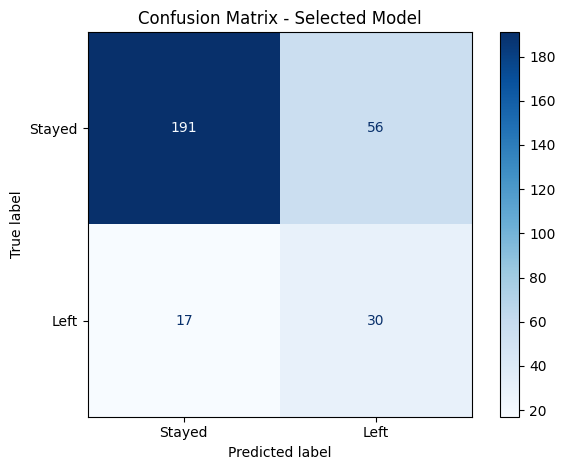

In [57]:
#4. Classification report and Confusion matrix

from sklearn.metrics import (
    classification_report,
    ConfusionMatrixDisplay
)

y_pred_best = best_model.predict(X_test)

print(classification_report(
    y_test,
    y_pred_best,
    labels=[0, 1],
    target_names=["Stayed", "Left"],
    zero_division=0
))

ConfusionMatrixDisplay.from_estimator(
    best_model,
    X_test,
    y_test,
    display_labels=["Stayed", "Left"],
    cmap="Blues"
)

plt.title("Confusion Matrix - Selected Model")
plt.tight_layout()
plt.show()

In [59]:
#Saving the model

import joblib
from google.colab import files

joblib.dump(
    best_model,
    "employee_attrition_model.pkl"
)

files.download("employee_attrition_model.pkl")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>